In [1]:
# 1. Rileva se il notebook è in esecuzione su Google Colab
import os
import sys
import subprocess

# 1. Rileva se il notebook è in esecuzione su Google Colab
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# 2. Esegui le istruzioni condizionali solo su Colab
if IN_COLAB:
    print("Google Colab rilevato: configurazione dell'ambiente in corso...")
    
    # Installazione di skrl
    subprocess.run(["pip", "install", "-q", "skrl"], check=True)
    
    # Clonazione o aggiornamento del repository DetectorOptimizer
    repo_name = "DetectorOptimizer"
    repo_url = "https://github.com/Stelfano/DetectorOptimizer.git"
    
    if not os.path.exists(repo_name):
        print(f"Clonazione del repository {repo_url}...")
        subprocess.run(["git", "clone", repo_url], check=True)
    else:
        print(f"La cartella '{repo_name}' esiste già. Aggiornamento in corso...")
        subprocess.run(["git", "-C", repo_name, "pull"], check=True)
        
    # Aggiunge la cartella del repository al Python path per poter importare i moduli
    repo_path = os.path.abspath(repo_name) if 'os.path-abspath' not in globals() else os.path.abspath(repo_name)
    # Nota: usiamo os.path.abspath standard
    repo_path = os.path.abspath(repo_name)
    if repo_path not in sys.path:
        sys.path.append(repo_path)
        
    # Installazione automatica delle dipendenze del repository (se presenti)
    requirements_path = os.path.join(repo_name, "requirements.txt")
    if os.path.exists(requirements_path):
        print("Installazione delle dipendenze da requirements.txt...")
        subprocess.run(["pip", "install", "-q", "-r", requirements_path], check=True)
        
    # Avvio di TensorBoard tramite le magie di IPython
    try:
        get_ipython().run_line_magic("load_ext", "tensorboard")
        get_ipython().run_line_magic("tensorboard", "--logdir runs")
        print("TensorBoard avviato con successo.")
    except Exception as e:
        print(f"Impossibile avviare automaticamente TensorBoard: {e}")
else:
    print("Ambiente locale rilevato: salto il download del repository e l'avvio di TensorBoard.")

Ambiente locale rilevato: salto il download del repository e l'avvio di TensorBoard.


In [2]:
from include.envs import SimpleRoTDetector, classicalOptimizingDetector, SimplePotentialDetector

env = SimplePotentialDetector(n_tracks=100, spatial_res=0.1, time_res=0.3, tof_margin=50.0)

In [3]:
from skrl.models.torch import Model, DeterministicMixin
from torch import nn
import torch


class Actor(DeterministicMixin, Model):
    def __init__(self, observation_space, action_space, device):
        Model.__init__(self, observation_space=observation_space, action_space=action_space, device=device)
        DeterministicMixin.__init__(self, clip_actions=True)

        self.net = nn.Sequential(
            nn.Linear(self.num_observations, 2**10), nn.ReLU(),
            nn.Linear(2**10, 2**12), nn.ReLU(),
            nn.Linear(2**12, 2**10), nn.ReLU(),
            nn.Linear(2**10, self.num_actions), nn.Tanh(),
        )

    def compute(self, inputs, role=""):
        return self.net(inputs["observations"]), {}


class Critic(DeterministicMixin, Model):
    def __init__(self, observation_space, action_space, device):
        Model.__init__(self, observation_space=observation_space, action_space=action_space, device=device)
        DeterministicMixin.__init__(self, clip_actions=False)

        self.net = nn.Sequential(
            nn.Linear(self.num_observations + self.num_actions, 2**12), nn.ReLU(),
            nn.Linear(2**12, 2**10), nn.ReLU(),
            nn.Linear(2**10, 2**8), nn.ReLU(),
            nn.Linear(2**8, 1),
        )

    def compute(self, inputs, role=""):
        x = torch.cat([inputs["observations"], inputs["taken_actions"]], dim=-1)
        return self.net(x), {}


In [4]:
from skrl.envs.wrappers.torch import wrap_env
from skrl.memories.torch import RandomMemory
from skrl.resources.noises.torch import GaussianNoise
from skrl.agents.torch.ddpg import DDPG, DDPG_CFG

device = "cuda" if torch.cuda.is_available() else "cpu"

env = wrap_env(env, wrapper = 'gymnasium')
memory = RandomMemory(memory_size=20000, num_envs=env.num_envs, device=device)

models = {
    "policy": Actor(env.observation_space, env.action_space, device),
    "target_policy": Actor(env.observation_space, env.action_space, device),
    "critic": Critic(env.observation_space, env.action_space, device),
    "target_critic": Critic(env.observation_space, env.action_space, device),
}

cfg = DDPG_CFG(
    batch_size=128,
    discount_factor=0,
    polyak=0.01,
    learning_rate=1e-4,
    random_timesteps=1000,
    learning_starts=2000,
    exploration_noise=GaussianNoise,
    exploration_noise_kwargs={"mean": 0.0, "std": 0.2, "device": device},
)
cfg.experiment.write_interval = 20
cfg.experiment.checkpoint_interval = 0
cfg.experiment.experiment_name = "ddpg_RoT-stable"
cfg.experiment.directory = "./runs"
cfg.close_environment_at_exit = True
cfg.timesteps = 50000
cfg.disable_progressbar = False
cfg.headless = True
cfg.environment_info = True

agent = DDPG(
    models=models,
    memory=memory,
    observation_space=env.observation_space,
    action_space=env.action_space,
    device=device,
    cfg=cfg,
)


[skrl:INFO] Environment wrapper: Gymnasium
[skrl:WARNING] Failed to check for a vectorized environment: module 'gymnasium.experimental' has no attribute 'vector'


  2%|▏         | 974/50000 [00:00<00:32, 1505.75it/s]

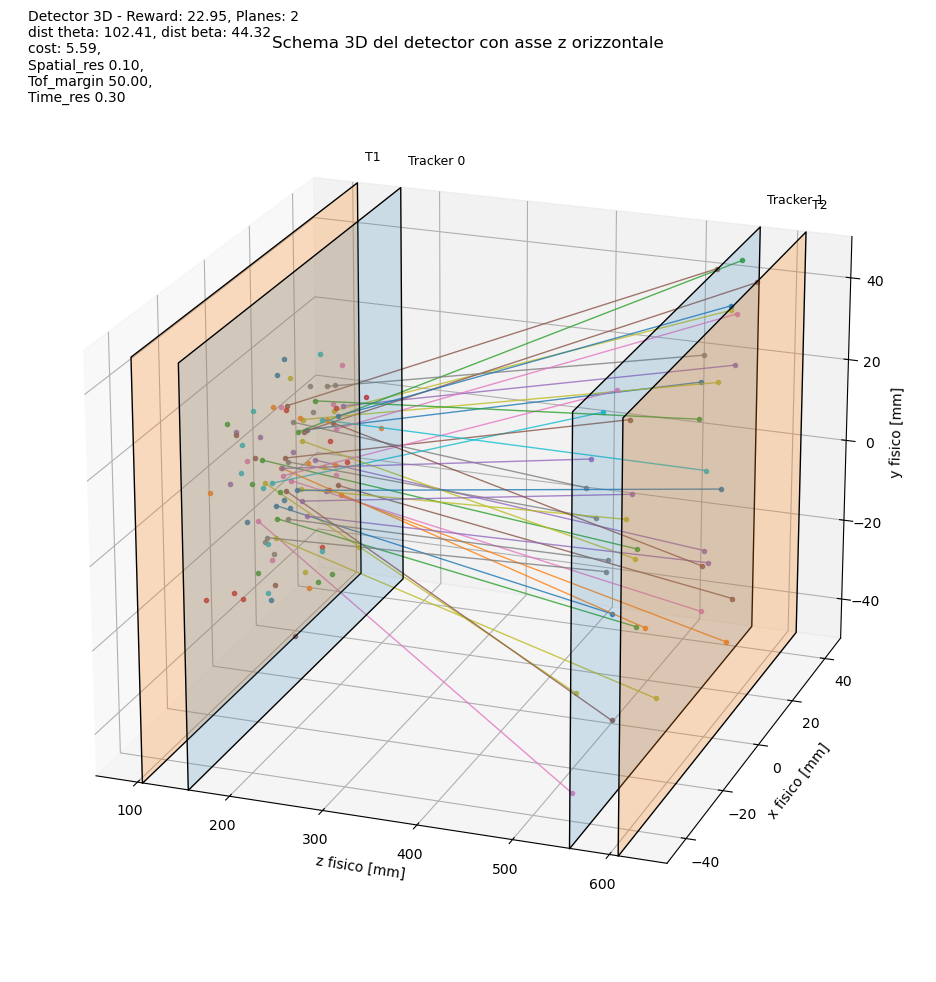

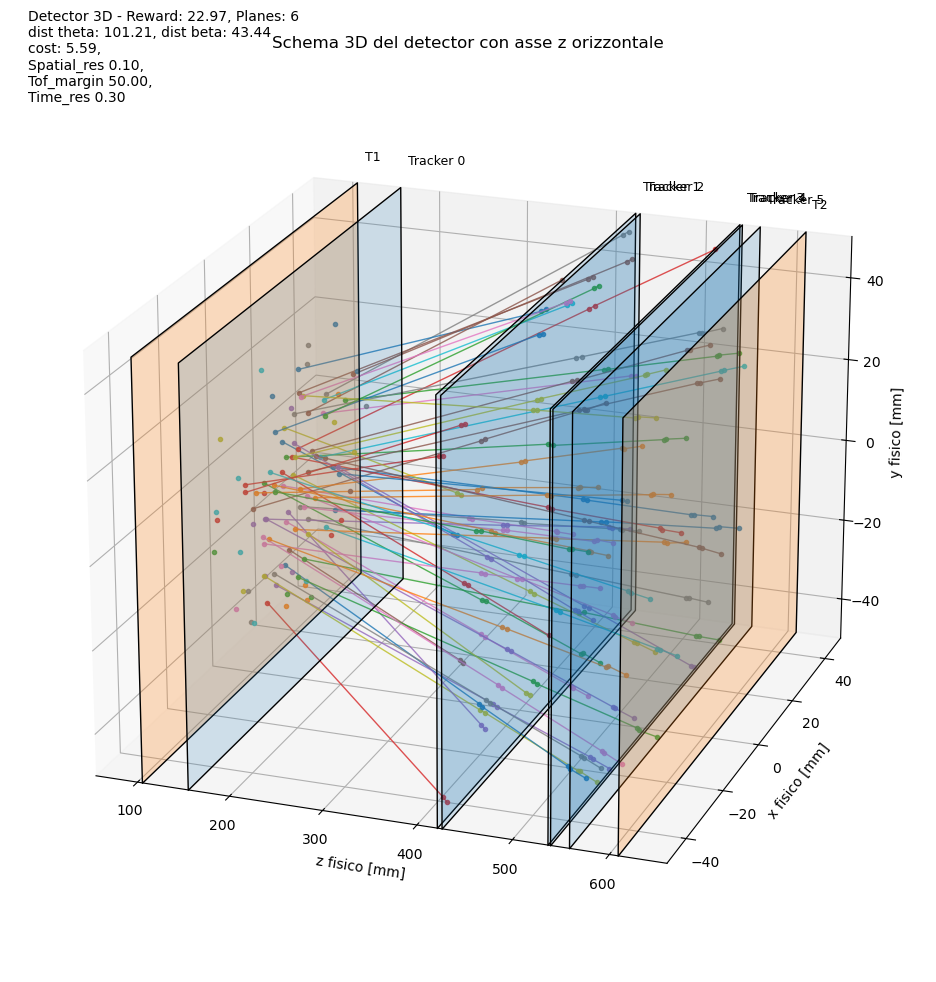

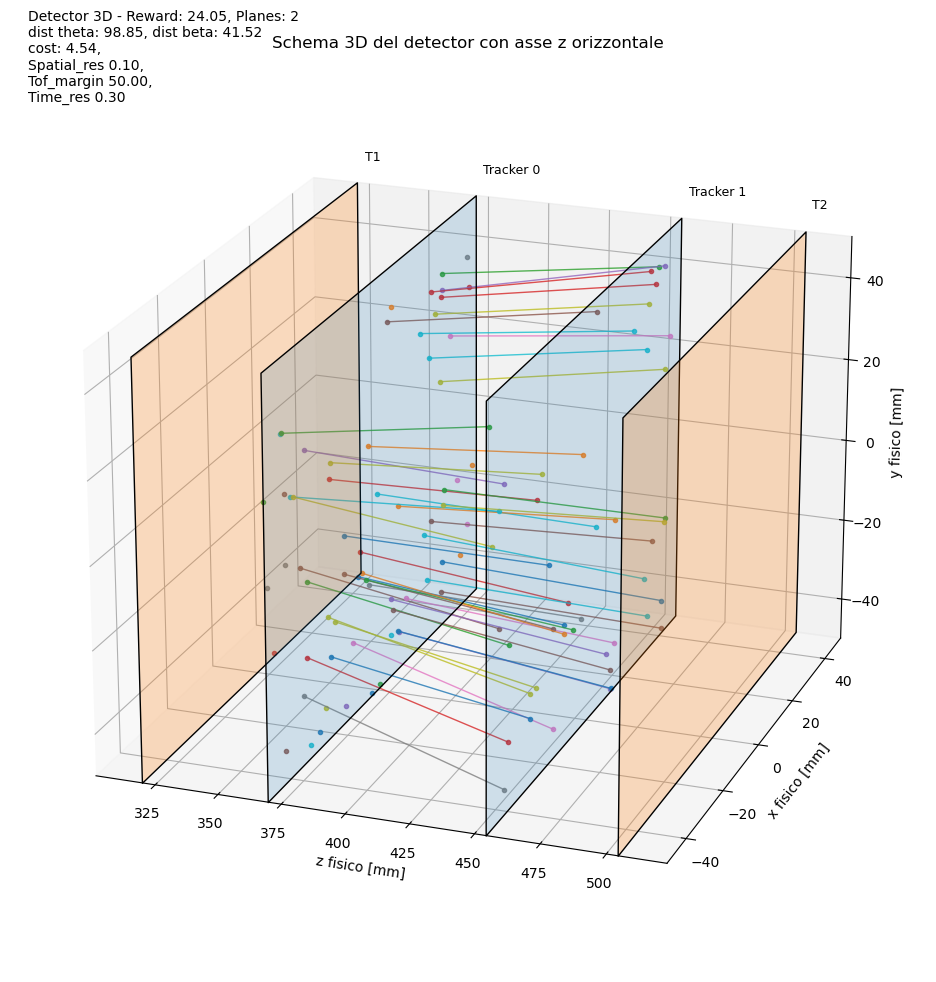

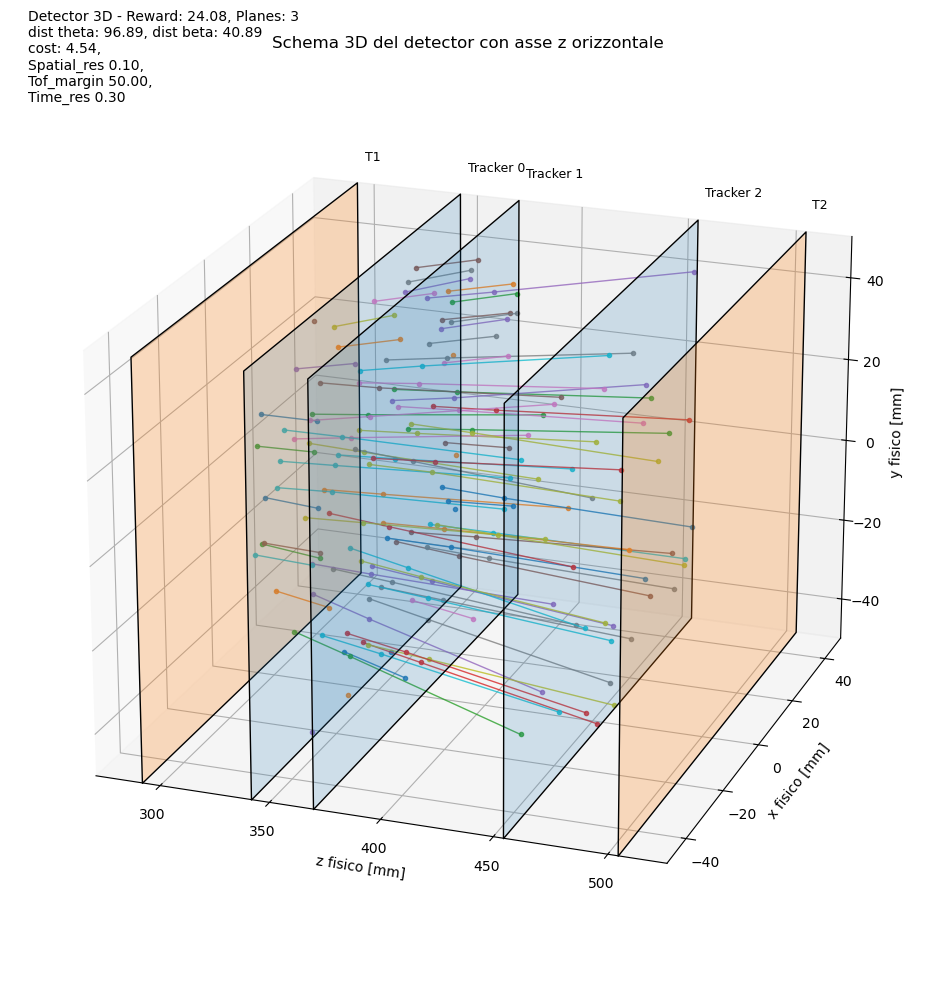

  2%|▏         | 1126/50000 [00:03<05:51, 138.92it/s]

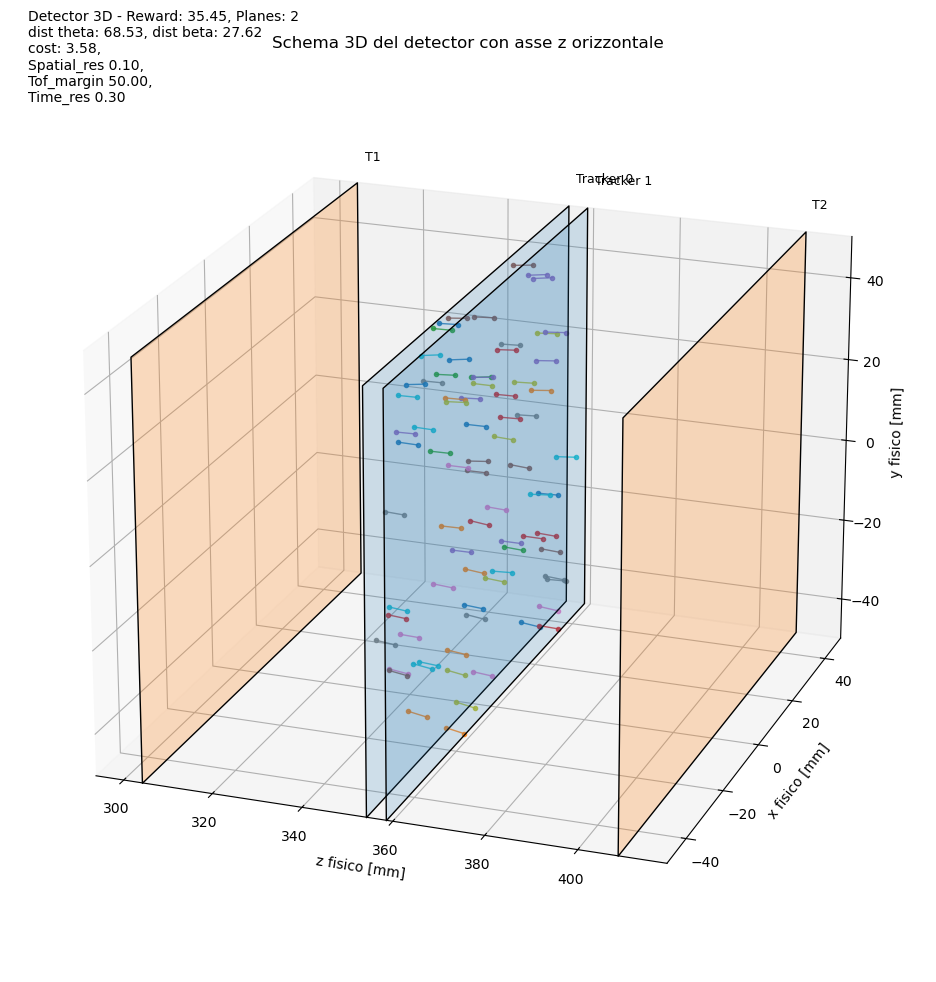

  4%|▍         | 1932/50000 [00:11<09:53, 81.04it/s] 

KeyboardInterrupt: 

  4%|▍         | 1933/50000 [00:29<09:53, 81.04it/s]

In [5]:
from include.misc import customTrainer

custom = customTrainer(env, agent, cfg, logdir='runs', health_logs=True)
custom.train()